In [6]:
import sys
from importlib.metadata import version

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold

SEED = 3242
CAPACITY = 0.10

pd.set_option("display.max_columns", None)

plt.rcParams["figure.figsize"] = (9, 5)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.2

print("Python:", sys.version)
print("Environment:", sys.executable)
print("SEED:", SEED)

for package in [
    "numpy", "scipy", "pandas",
    "matplotlib", "scikit-learn", "joblib"
]:
    print(package, version(package))

Python: 3.12.10 (tags/v3.12.10:0cc8128, Apr  8 2025, 12:21:36) [MSC v.1943 64 bit (AMD64)]
Environment: c:\Users\user\Downloads\gumar_ML_task_3\.gumar_ML_task_3\Scripts\python.exe
SEED: 3242
numpy 2.3.4
scipy 1.16.3
pandas 2.3.3
matplotlib 3.10.7
scikit-learn 1.7.2
joblib 1.5.2


In [7]:
train = pd.read_csv("data/train.csv")
test = pd.read_csv("data/test.csv")

print("Train shape:", train.shape)
print("Test shape:", test.shape)

print("\nColumns only in train:")
print(sorted(set(train.columns) - set(test.columns)))

print("\nColumns only in test:")
print(sorted(set(test.columns) - set(train.columns)))

print("\nTarget values:")
print(train["y"].value_counts())

assert train["id"].is_unique
assert test["id"].is_unique
assert set(train["id"]).isdisjoint(set(test["id"]))
assert set(train["y"].unique()) == {"yes", "no"}
assert set(train.columns) - set(test.columns) == {"duration", "y"}

display(train.head())

Train shape: (32940, 22)
Test shape: (8236, 20)

Columns only in train:
['duration', 'y']

Columns only in test:
[]

Target values:
y
no     29229
yes     3711
Name: count, dtype: int64


,id,age,job,marital,education,default,housing,loan,contact,month,day_of_week,duration,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,0,39,management,single,basic.9y,unknown,yes,no,telephone,may,tue,134,3,999,0,nonexistent,1.1,93.994,-36.4,4.856,5191.0,no
1,1,32,admin.,single,university.degree,no,yes,no,cellular,aug,mon,61,2,999,0,nonexistent,1.4,93.444,-36.1,4.963,5228.1,no
2,2,41,technician,married,high.school,no,no,yes,cellular,aug,fri,210,1,999,0,nonexistent,1.4,93.444,-36.1,4.963,5228.1,no
3,3,39,admin.,married,professional.course,no,yes,yes,telephone,may,wed,72,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,4,51,blue-collar,married,basic.9y,unknown,no,no,telephone,jun,wed,119,1,999,0,nonexistent,1.4,94.465,-41.8,4.864,5228.1,no


 Input columns and leakage . The training file has two extra columns: y and duration.
 - y is the target, so it is not an input feature.
- duration is the call length. It is unknown before the call.
  Using it would cause data leakage.
- id identifies a row. It is not a useful client feature.

The model will use the 19 features available in test.csv,
excluding id.

In [11]:
feature_columns = [
    column for column in test.columns
    if column != "id"
]

X = train[feature_columns].copy()
y = train["y"].map({"no": 0, "yes": 1})

X_test = test[feature_columns].copy()

X_train, X_holdout, y_train, y_holdout = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=SEED,
    stratify=y
)

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=SEED
)

cv_splits = list(cv.split(X_train, y_train))

assert X_train.index.intersection(X_holdout.index).empty
assert list(X_train.columns) == list(X_test.columns)
assert "duration" not in X_train.columns
assert "id" not in X_train.columns

print("Development training set:", X_train.shape)
print("Hold-out set:", X_holdout.shape)
print("Hidden test set:", X_test.shape)
print("Number of CV folds:", len(cv_splits))

print("\nPositive class in training:",
      f"{y_train.mean():.2%}")
print("Positive class in hold-out:",
      f"{y_holdout.mean():.2%}")

Development training set: (26352, 19)
Hold-out set: (6588, 19)
Hidden test set: (8236, 19)
Number of CV folds: 5

Positive class in training: 11.27%
Positive class in hold-out: 11.26%


In [9]:
eda = X_train.copy()
eda["y"] = y_train

class_counts = y_train.value_counts().reindex([0, 1])

class_summary = pd.DataFrame({
    "class": ["no", "yes"],
    "count": class_counts.to_numpy(),
    "percent": 100 * class_counts.to_numpy() / len(y_train)
})

display(class_summary.round(2))

majority_accuracy = (y_train == 0).mean()

print(f"Always-no accuracy: {majority_accuracy:.2%}")

missing_summary = pd.DataFrame({
    "dtype": X_train.dtypes.astype(str),
    "NaN_count": X_train.isna().sum(),
    "unknown_count": X_train.eq("unknown").sum()
})

display(missing_summary)

sentinel_count = X_train["pdays"].eq(999).sum()

print("pdays = 999 count:", sentinel_count)
print(f"pdays = 999 share: {sentinel_count / len(X_train):.2%}")

print(
    "Rows duplicated across available features:",
    X_train.duplicated().sum()
)

,class,count,percent
0,no,23383,88.73
1,yes,2969,11.27


Always-no accuracy: 88.73%


,dtype,NaN_count,unknown_count
age,int64,0,0
job,object,0,215
marital,object,0,54
education,object,0,1130
default,object,0,5498
housing,object,0,631
loan,object,0,631
contact,object,0,0
month,object,0,0
day_of_week,object,0,0


pdays = 999 count: 25331
pdays = 999 share: 96.13%
Rows duplicated across available features: 861


,clients,yes_count,yes_rate
poutcome,,,
nonexistent,22726,1988,0.0875
failure,2705,381,0.1409
success,921,600,0.6515


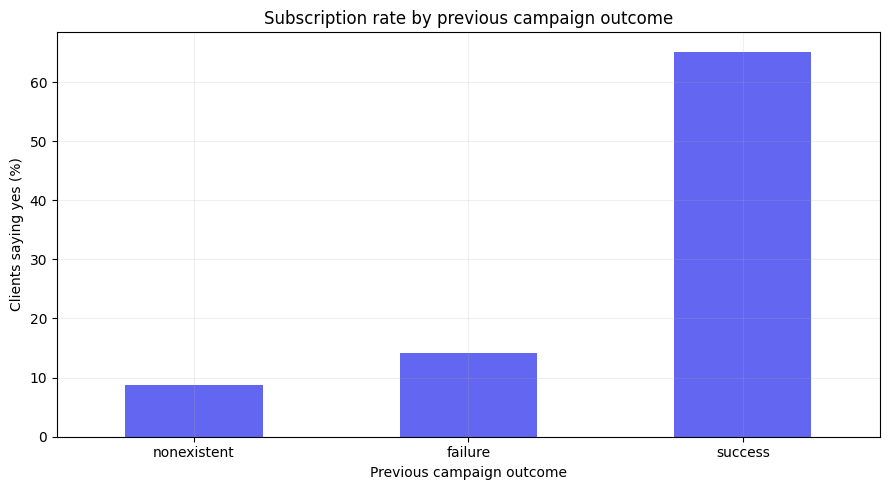

nonexistent: 8.75% said yes among 22726 clients.
failure: 14.09% said yes among 2705 clients.
success: 65.15% said yes among 921 clients.


In [10]:
previous_summary = (
    eda.groupby("poutcome")["y"]
    .agg(["count", "sum", "mean"])
    .rename(columns={
        "count": "clients",
        "sum": "yes_count",
        "mean": "yes_rate"
    })
    .sort_values("yes_rate")
)

display(previous_summary.round(4))

ax = (100 * previous_summary["yes_rate"]).plot(
    kind="bar",
    color="#6366f1",
    rot=0
)

ax.set_title("Subscription rate by previous campaign outcome")
ax.set_xlabel("Previous campaign outcome")
ax.set_ylabel("Clients saying yes (%)")

plt.tight_layout()
plt.show()

for group, row in previous_summary.iterrows():
    print(
        f"{group}: {row['yes_rate']:.2%} said yes "
        f"among {int(row['clients'])} clients."
    )

In [12]:
print("Train IDs sorted ascending:",
      train["id"].is_monotonic_increasing)

print("First 15 months in the supplied training file:")
print(train["month"].head(15).tolist())

print("\nMonth counts in the development training set:")
print(X_train["month"].value_counts())

Train IDs sorted ascending: True
First 15 months in the supplied training file:
['may', 'aug', 'aug', 'may', 'jun', 'aug', 'may', 'apr', 'jul', 'nov', 'nov', 'sep', 'aug', 'jul', 'aug']

Month counts in the development training set:
month
may    8797
jul    4615
aug    3952
jun    3381
nov    2623
apr    1678
oct     452
mar     371
sep     366
dec     117
Name: count, dtype: int64


Data limitations

The starter README says the data were split randomly
and the id values were shuffled.
We cannot use id as a time variable.
Month and day_of_week do not provide a complete date.
We should not assume that the supplied row order is chronological. 
Random validation mixes observations from historical periods.
In real use, the bank trains on the past and predicts the future.
Changes in the economy or client behaviour may reduce performance.
Our random-split results may therefore be optimistic.
The value unknown represents missing information.
The value pdays = 999 means no previous contact.
We will handle both explicitly inside the pipeline.

In [13]:
print("SEED:", SEED)

print("\nShapes:")
print("Training:", X_train.shape)
print("Hold-out:", X_holdout.shape)
print("Hidden test:", X_test.shape)

print("\nClass balance:")
display(class_summary.round(2))

print("\nMissing values:")
display(
    missing_summary.loc[
        (missing_summary["NaN_count"] > 0)
        | (missing_summary["unknown_count"] > 0)
    ]
)

print("\npdays = 999:", sentinel_count)

print("\nPrevious campaign results:")
display(previous_summary.round(4))

SEED: 3242

Shapes:
Training: (26352, 19)
Hold-out: (6588, 19)
Hidden test: (8236, 19)

Class balance:


,class,count,percent
0,no,23383,88.73
1,yes,2969,11.27



Missing values:


,dtype,NaN_count,unknown_count
job,object,0,215
marital,object,0,54
education,object,0,1130
default,object,0,5498
housing,object,0,631
loan,object,0,631



pdays = 999: 25331

Previous campaign results:


,clients,yes_count,yes_rate
poutcome,,,
nonexistent,22726,1988,0.0875
failure,2705,381,0.1409
success,921,600,0.6515


In [14]:
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.model_selection import cross_validate

In [15]:
categorical_columns = X_train.select_dtypes(
    include=["object", "string", "category"]
).columns.tolist()

numeric_columns = [
    column
    for column in X_train.select_dtypes(include="number").columns
    if column != "pdays"
]

print("Categorical:", categorical_columns)
print("Numeric:", numeric_columns)
print("Special column: pdays")


def make_preprocessor(unknown_strategy="keep"):
    numeric_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ])

    pdays_pipeline = Pipeline([
        ("imputer", SimpleImputer(
            missing_values=999,
            strategy="median",
            add_indicator=True
        )),
        ("scaler", StandardScaler())
    ])

    if unknown_strategy == "keep":
        categorical_pipeline = Pipeline([
            ("imputer", SimpleImputer(
                strategy="constant",
                fill_value="unknown"
            )),
            ("encoder", OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            ))
        ])

    elif unknown_strategy == "mode":
        categorical_pipeline = Pipeline([
            ("imputer", SimpleImputer(
                missing_values="unknown",
                strategy="most_frequent"
            )),
            ("encoder", OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            ))
        ])

    else:
        raise ValueError("Use 'keep' or 'mode'.")

    return ColumnTransformer([
        ("numeric", numeric_pipeline, numeric_columns),
        ("pdays", pdays_pipeline, ["pdays"]),
        ("categorical", categorical_pipeline, categorical_columns)
    ])


def make_model(model, unknown_strategy="keep"):
    return Pipeline([
        ("preprocess", make_preprocessor(unknown_strategy)),
        ("model", model)
    ])

Categorical: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'poutcome']
Numeric: ['age', 'campaign', 'previous', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed']
Special column: pdays


In [16]:
def top_capacity_predictions(scores, capacity=CAPACITY):
    scores = np.asarray(scores)

    n_calls = max(1, int(np.floor(capacity * len(scores))))

    # Fixed random order to resolve equal scores without using labels.
    rng = np.random.default_rng(SEED)
    shuffled_indices = rng.permutation(len(scores))

    ranking = shuffled_indices[
        np.argsort(-scores[shuffled_indices], kind="stable")
    ]

    predictions = np.zeros(len(scores), dtype=int)
    predictions[ranking[:n_calls]] = 1

    return predictions


def precision_at_capacity(estimator, features, target):
    scores = estimator.predict_proba(features)[:, 1]
    selected = top_capacity_predictions(scores).astype(bool)

    return np.asarray(target)[selected].mean()


scoring = {
    "precision_at_10": precision_at_capacity,
    "roc_auc": "roc_auc",
    "average_precision": "average_precision",
    "accuracy": "accuracy"
}

In [17]:
candidates = {
    "Dummy": make_model(
        DummyClassifier(strategy="most_frequent")
    ),

    "Logistic": make_model(
        LogisticRegression(
            max_iter=3000,
            random_state=SEED
        )
    ),

    "Decision tree": make_model(
        DecisionTreeClassifier(
            max_depth=6,
            min_samples_leaf=30,
            random_state=SEED
        )
    ),

    "Random forest": make_model(
        RandomForestClassifier(
            n_estimators=200,
            max_depth=12,
            min_samples_leaf=10,
            random_state=SEED,
            n_jobs=-1
        )
    ),

    "Logistic balanced": make_model(
        LogisticRegression(
            max_iter=3000,
            class_weight="balanced",
            random_state=SEED
        )
    ),

    "Logistic unknown=mode": make_model(
        LogisticRegression(
            max_iter=3000,
            random_state=SEED
        ),
        unknown_strategy="mode"
    )
}

In [18]:
cv_results = {}
summary_rows = []

for name, pipeline in candidates.items():
    print(f"Running: {name}", flush=True)

    result = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=cv_splits,
        scoring=scoring,
        n_jobs=1,
        error_score="raise"
    )

    cv_results[name] = result

    row = {"model": name}

    for metric in scoring:
        fold_values = result[f"test_{metric}"]

        row[f"{metric}_mean"] = fold_values.mean()
        row[f"{metric}_std"] = fold_values.std(ddof=1)

    summary_rows.append(row)

    print(
        "Finished. Precision@10%:",
        f"{row['precision_at_10_mean']:.4f}",
        "+/-",
        f"{row['precision_at_10_std']:.4f}",
        flush=True
    )

comparison = (
    pd.DataFrame(summary_rows)
    .set_index("model")
    .sort_values("precision_at_10_mean", ascending=False)
)

display(comparison.round(4))

Running: Dummy
Finished. Precision@10%: 0.1116 +/- 0.0181
Running: Logistic
Finished. Precision@10%: 0.4994 +/- 0.0271
Running: Decision tree
Finished. Precision@10%: 0.4994 +/- 0.0259
Running: Random forest
Finished. Precision@10%: 0.5108 +/- 0.0217
Running: Logistic balanced
Finished. Precision@10%: 0.4987 +/- 0.0218
Running: Logistic unknown=mode
Finished. Precision@10%: 0.4991 +/- 0.0276


,precision_at_10_mean,precision_at_10_std,roc_auc_mean,roc_auc_std,average_precision_mean,average_precision_std,accuracy_mean,accuracy_std
model,,,,,,,,
Random forest,0.5108,0.0217,0.8000,0.0145,0.4741,0.0303,0.9005,0.0025
Logistic,0.4994,0.0271,0.7909,0.0135,0.4530,0.0281,0.9003,0.0019
Decision tree,0.4994,0.0259,0.7889,0.0154,0.4262,0.0248,0.8985,0.0023
Logistic unknown=mode,0.4991,0.0276,0.7908,0.0136,0.4522,0.0292,0.9003,0.0018
Logistic balanced,0.4987,0.0218,0.7911,0.0140,0.4469,0.0260,0.8254,0.0030
Dummy,0.1116,0.0181,0.5000,0.0000,0.1127,0.0001,0.8873,0.0001


,Dummy,Logistic,Decision tree,Random forest,Logistic balanced,Logistic unknown=mode
Fold 1,0.1233,0.4991,0.5066,0.5104,0.4915,0.4953
Fold 2,0.1006,0.4744,0.4706,0.4839,0.4782,0.4725
Fold 3,0.1139,0.4706,0.4744,0.4953,0.4801,0.4725
Fold 4,0.0873,0.5237,0.5294,0.5313,0.5237,0.5294
Fold 5,0.1328,0.5294,0.5161,0.5332,0.5199,0.5256


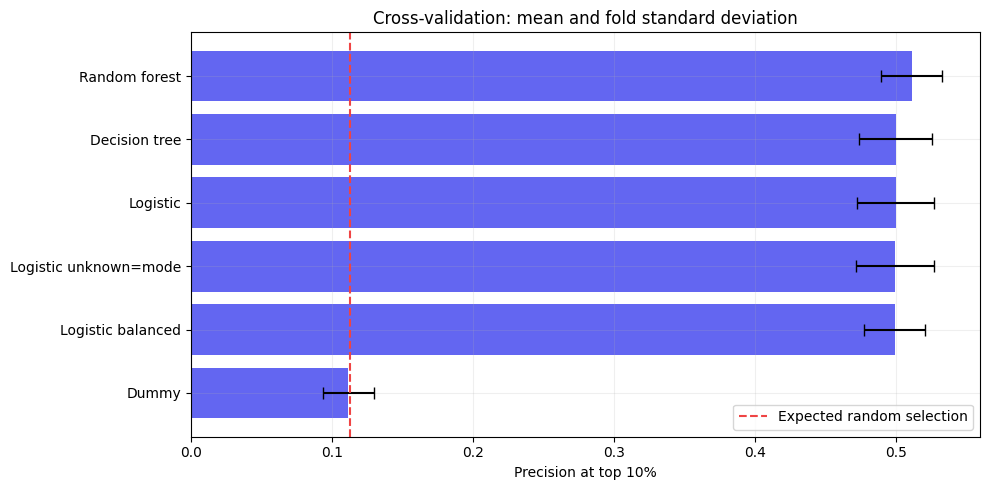

Random forest: 51.08% +/- 2.17%
Logistic: 49.94% +/- 2.71%
Decision tree: 49.94% +/- 2.59%
Logistic unknown=mode: 49.91% +/- 2.76%
Logistic balanced: 49.87% +/- 2.18%
Dummy: 11.16% +/- 1.81%


In [19]:
fold_precision = pd.DataFrame({
    name: result["test_precision_at_10"]
    for name, result in cv_results.items()
})

fold_precision.index = [
    f"Fold {i + 1}" for i in range(len(cv_splits))
]

display(fold_precision.round(4))

plot_data = comparison.sort_values("precision_at_10_mean")

fig, ax = plt.subplots(figsize=(10, 5))

ax.barh(
    plot_data.index,
    plot_data["precision_at_10_mean"],
    xerr=plot_data["precision_at_10_std"],
    capsize=4,
    color="#6366f1"
)

ax.axvline(
    y_train.mean(),
    color="#ef4444",
    linestyle="--",
    label="Expected random selection"
)

ax.set_xlabel("Precision at top 10%")
ax.set_title("Cross-validation: mean and fold standard deviation")
ax.legend()

plt.tight_layout()
plt.show()

for name, row in comparison.iterrows():
    print(
        f"{name}: "
        f"{row['precision_at_10_mean']:.2%} "
        f"+/- {row['precision_at_10_std']:.2%}"
    )

In [20]:
from sklearn.model_selection import GridSearchCV

parameter_grids = {
    "Logistic": {
        "model__C": [0.01, 0.1, 1.0, 10.0]
    },

    "Random forest": {
        "model__max_depth": [8, 12, None],
        "model__min_samples_leaf": [10, 30]
    }
}

for name, grid in parameter_grids.items():
    print(name)
    print(grid)

Logistic
{'model__C': [0.01, 0.1, 1.0, 10.0]}
Random forest
{'model__max_depth': [8, 12, None], 'model__min_samples_leaf': [10, 30]}


In [21]:
searches = {}

for name, grid in parameter_grids.items():
    print(f"\nTuning: {name}", flush=True)

    search = GridSearchCV(
        estimator=clone(candidates[name]),
        param_grid=grid,
        scoring=scoring,
        refit="precision_at_10",
        cv=cv_splits,
        n_jobs=1,
        verbose=1,
        error_score="raise",
        return_train_score=False
    )

    search.fit(X_train, y_train)
    searches[name] = search

    print("Best parameters:", search.best_params_)
    print(
        "Best mean CV precision@10%:",
        f"{search.best_score_:.4f}"
    )


Tuning: Logistic
Fitting 5 folds for each of 4 candidates, totalling 20 fits
Best parameters: {'model__C': 1.0}
Best mean CV precision@10%: 0.4994

Tuning: Random forest
Fitting 5 folds for each of 6 candidates, totalling 30 fits
Best parameters: {'model__max_depth': 12, 'model__min_samples_leaf': 10}
Best mean CV precision@10%: 0.5108


In [22]:
tuning_tables = []

for name, search in searches.items():
    results = pd.DataFrame(search.cv_results_)

    table = results[[
        "params",
        "mean_test_precision_at_10",
        "std_test_precision_at_10",
        "mean_test_roc_auc",
        "mean_test_average_precision"
    ]].copy()

    # Use sample standard deviation, as in the earlier comparison.
    fold_columns = [
        f"split{i}_test_precision_at_10"
        for i in range(len(cv_splits))
    ]

    table["std_test_precision_at_10"] = (
        results[fold_columns].std(axis=1, ddof=1)
    )

    table.insert(0, "model", name)
    tuning_tables.append(table)

tuning_results = (
    pd.concat(tuning_tables, ignore_index=True)
    .sort_values("mean_test_precision_at_10", ascending=False)
)

display(tuning_results.round(4))

,model,params,mean_test_precision_at_10,std_test_precision_at_10,mean_test_roc_auc,mean_test_average_precision
6,Random forest,"{'model__max_depth': 12, 'model__min_samples_l...",0.5108,0.0217,0.8000,0.4741
8,Random forest,"{'model__max_depth': None, 'model__min_samples...",0.5104,0.0239,0.7987,0.4750
9,Random forest,"{'model__max_depth': None, 'model__min_samples...",0.5036,0.0288,0.7980,0.4686
4,Random forest,"{'model__max_depth': 8, 'model__min_samples_le...",0.5025,0.0243,0.7987,0.4698
7,Random forest,"{'model__max_depth': 12, 'model__min_samples_l...",0.5017,0.0257,0.7988,0.4692
5,Random forest,"{'model__max_depth': 8, 'model__min_samples_le...",0.4998,0.0236,0.7977,0.4651
2,Logistic,{'model__C': 1.0},0.4994,0.0271,0.7909,0.4530
3,Logistic,{'model__C': 10.0},0.4979,0.0281,0.7907,0.4531
1,Logistic,{'model__C': 0.1},0.4972,0.0247,0.7908,0.4532
0,Logistic,{'model__C': 0.01},0.4873,0.0248,0.7893,0.4500


In [23]:
best_fold_scores = pd.DataFrame({
    name: [
        search.cv_results_[
            f"split{i}_test_precision_at_10"
        ][search.best_index_]
        for i in range(len(cv_splits))
    ]
    for name, search in searches.items()
})

best_fold_scores.index = [
    f"Fold {i + 1}" for i in range(len(cv_splits))
]

best_fold_scores["Forest minus Logistic"] = (
    best_fold_scores["Random forest"]
    - best_fold_scores["Logistic"]
)

display(best_fold_scores.round(4))

difference = best_fold_scores["Forest minus Logistic"]

print(
    "Mean forest advantage:",
    f"{100 * difference.mean():.2f} percentage points"
)

print(
    "Standard deviation of paired differences:",
    f"{100 * difference.std(ddof=1):.2f} percentage points"
)

print(
    "Folds where forest scores higher:",
    int((difference > 0).sum()),
    "out of",
    len(difference)
)

,Logistic,Random forest,Forest minus Logistic
Fold 1,0.4991,0.5104,0.0114
Fold 2,0.4744,0.4839,0.0095
Fold 3,0.4706,0.4953,0.0247
Fold 4,0.5237,0.5313,0.0076
Fold 5,0.5294,0.5332,0.0038


Mean forest advantage: 1.14 percentage points
Standard deviation of paired differences: 0.79 percentage points
Folds where forest scores higher: 5 out of 5


i select random forest with 200 trees, max_depth=12
and min_samples_leaf=10.
Its mean CV precision at the top 10% is 0.5108.
The best logistic regression scores 0.4994.
The forest scores higher on all five folds.
The mean paired difference is 0.0114, with a standard deviation
of 0.0079. However, the folds have overlapping training sets.
This is not proof of statistical superiority.
The forest with unlimited depth scores 0.5104.
This difference is negligible compared with the fold spread.
i prefer the depth-limited model.
i keep unknown as a category and use no class weighting.
The preprocessing and model choices are now fixed.
i will evaluate only this selected model on the hold-out.

In [24]:
fold_train_indices, fold_valid_indices = cv_splits[0]

fold_X_train = X_train.iloc[fold_train_indices]
fold_y_train = y_train.iloc[fold_train_indices]

# Use a simple model to inspect the same preprocessing.
fold_check = clone(candidates["Logistic"])
fold_check.fit(fold_X_train, fold_y_train)

fitted_preprocessor = fold_check.named_steps["preprocess"]

learned_medians = (
    fitted_preprocessor
    .named_transformers_["numeric"]
    .named_steps["imputer"]
    .statistics_
)

expected_medians = fold_X_train[numeric_columns].median().to_numpy()

np.testing.assert_allclose(
    learned_medians,
    expected_medians
)

learned_pdays_median = (
    fitted_preprocessor
    .named_transformers_["pdays"]
    .named_steps["imputer"]
    .statistics_[0]
)

expected_pdays_median = (
    fold_X_train.loc[fold_X_train["pdays"] != 999, "pdays"]
    .median()
)

np.testing.assert_allclose(
    learned_pdays_median,
    expected_pdays_median
)

assert set(fold_train_indices).isdisjoint(fold_valid_indices)

print("Training rows in fold:", len(fold_train_indices))
print("Validation rows in fold:", len(fold_valid_indices))
print("Learned pdays median:", learned_pdays_median)
print("Expected training-fold median:", expected_pdays_median)
print("Checks passed: medians match the training fold only.")

Training rows in fold: 21081
Validation rows in fold: 5271
Learned pdays median: 6.0
Expected training-fold median: 6.0
Checks passed: medians match the training fold only.


In [25]:
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    precision_score,
    recall_score,
    confusion_matrix,
    RocCurveDisplay,
    PrecisionRecallDisplay,
    ConfusionMatrixDisplay
)

selected_model_name = "Random forest"

# GridSearchCV already refitted this pipeline on all X_train.
selected_model = searches[selected_model_name].best_estimator_

holdout_scores = selected_model.predict_proba(X_holdout)[:, 1]

holdout_predictions = top_capacity_predictions(holdout_scores)

n_calls = int(holdout_predictions.sum())
selected_mask = holdout_predictions.astype(bool)

capacity_cutoff = holdout_scores[selected_mask].min()

holdout_auc = roc_auc_score(y_holdout, holdout_scores)
holdout_ap = average_precision_score(y_holdout, holdout_scores)

holdout_precision = precision_score(
    y_holdout, holdout_predictions, zero_division=0
)

holdout_recall = recall_score(
    y_holdout, holdout_predictions, zero_division=0
)

holdout_positive_rate = y_holdout.mean()
holdout_lift = holdout_precision / holdout_positive_rate

holdout_cm = confusion_matrix(
    y_holdout,
    holdout_predictions,
    labels=[0, 1]
)

tn, fp, fn, tp = holdout_cm.ravel()

holdout_metrics = pd.Series({
    "ROC-AUC": holdout_auc,
    "Average precision": holdout_ap,
    "Precision@10%": holdout_precision,
    "Recall@10%": holdout_recall,
    "Lift@10%": holdout_lift,
    "Positive class rate": holdout_positive_rate,
    "Selected share": n_calls / len(y_holdout),
    "Capacity cutoff": capacity_cutoff
})

display(holdout_metrics.round(4))

print("Hold-out clients:", len(y_holdout))
print("Clients selected for a call:", n_calls)
print("Selected clients who said yes:", tp)
print("Selected clients who said no:", fp)
print("Not selected, but said yes:", fn)
print("Not selected and said no:", tn)

print(
    "Clients tied at the cutoff:",
    int(np.sum(holdout_scores == capacity_cutoff))
)

ROC-AUC                0.7989
Average precision      0.4653
Precision@10%          0.5152
Recall@10%             0.4569
Lift@10%               4.5743
Positive class rate    0.1126
Selected share         0.0999
Capacity cutoff        0.3265
dtype: float64

Hold-out clients: 6588
Clients selected for a call: 658
Selected clients who said yes: 339
Selected clients who said no: 319
Not selected, but said yes: 403
Not selected and said no: 5527
Clients tied at the cutoff: 1


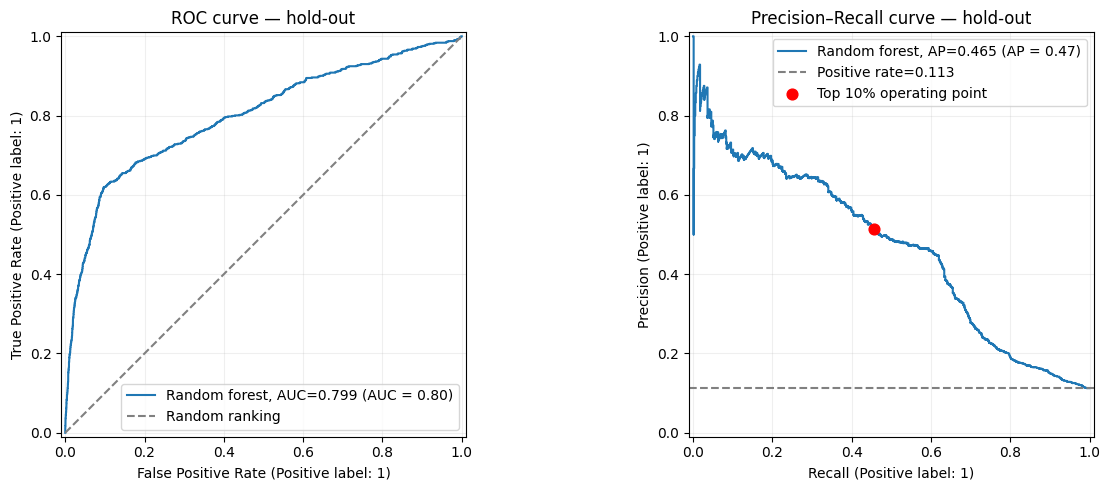

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

RocCurveDisplay.from_predictions(
    y_holdout,
    holdout_scores,
    ax=axes[0],
    name=f"Random forest, AUC={holdout_auc:.3f}"
)

axes[0].plot(
    [0, 1], [0, 1],
    linestyle="--",
    color="gray",
    label="Random ranking"
)

axes[0].set_title("ROC curve — hold-out")
axes[0].legend(loc="lower right")

PrecisionRecallDisplay.from_predictions(
    y_holdout,
    holdout_scores,
    ax=axes[1],
    name=f"Random forest, AP={holdout_ap:.3f}"
)

axes[1].axhline(
    holdout_positive_rate,
    linestyle="--",
    color="gray",
    label=f"Positive rate={holdout_positive_rate:.3f}"
)

axes[1].scatter(
    holdout_recall,
    holdout_precision,
    color="red",
    s=60,
    label="Top 10% operating point",
    zorder=5
)

axes[1].set_title("Precision–Recall curve — hold-out")
axes[1].legend()

plt.tight_layout()
plt.show()

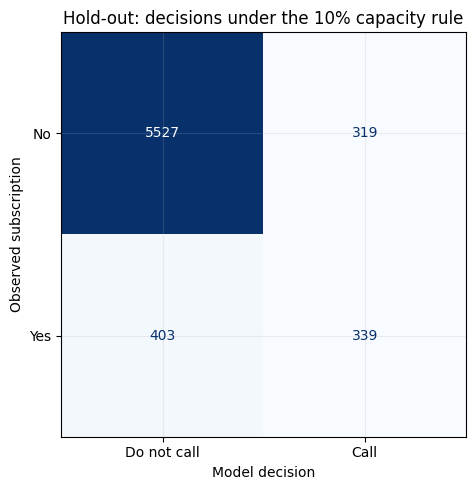

We selected 658 clients out of 6588.
Among selected clients, 339 said yes and 319 said no.
We did not select 403 clients who said yes.
Precision: 51.52%. Recall: 45.69%.
Random selection would find about 74.1 positive clients on average.
The model's lift over random selection is 4.57.


In [27]:
fig, ax = plt.subplots(figsize=(6, 5))

ConfusionMatrixDisplay(
    confusion_matrix=holdout_cm,
    display_labels=["No", "Yes"]
).plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    colorbar=False
)

ax.set_xticklabels(["Do not call", "Call"])
ax.set_xlabel("Model decision")
ax.set_ylabel("Observed subscription")
ax.set_title("Hold-out: decisions under the 10% capacity rule")

plt.tight_layout()
plt.show()

expected_random_yes = n_calls * holdout_positive_rate

print(
    f"We selected {n_calls} clients out of {len(y_holdout)}."
)

print(
    f"Among selected clients, {tp} said yes and {fp} said no."
)

print(
    f"We did not select {fn} clients who said yes."
)

print(
    f"Precision: {holdout_precision:.2%}. "
    f"Recall: {holdout_recall:.2%}."
)

print(
    f"Random selection would find about "
    f"{expected_random_yes:.1f} positive clients on average."
)

print(
    f"The model's lift over random selection is "
    f"{holdout_lift:.2f}."
)

The selected pipeline was evaluated on the reserved hold-out.
The call list contains the top 10% of scores, rounded down.
Equal scores are resolved using a fixed random order.

The cutoff is determined by capacity, not by maximising a metric
using the hold-out labels.

These results describe historical data.
They do not prove that the model increases sales in a new campaign.

Random splitting mixes historical periods.
Real deployment predicts future clients using past data.
Changes in the economy, customer behaviour or campaign design
may reduce performance.

After this evaluation, we will not change the model based on
hold-out results. We will refit the fixed pipeline on all labelled
data before creating the final test predictions.

In [28]:
import joblib
from pathlib import Path

final_model = clone(selected_model)
final_model.fit(X, y)

joblib.dump(final_model, "model.joblib", compress=3)

test_scores = final_model.predict_proba(X_test)[:, 1]
test_predictions = top_capacity_predictions(test_scores)

predictions = pd.DataFrame({
    "id": test["id"].to_numpy(),
    "y_pred": test_predictions,
    "y_score": test_scores
})

assert len(predictions) == len(test)
assert predictions["id"].is_unique
assert predictions["id"].tolist() == test["id"].tolist()
assert set(predictions["y_pred"].unique()).issubset({0, 1})
assert np.isfinite(predictions["y_score"]).all()

assert predictions["y_pred"].sum() == int(
    np.floor(CAPACITY * len(test))
)

predictions.to_csv("predictions.csv", index=False)

model_size = Path("model.joblib").stat().st_size

assert model_size < 50_000_000

print("Model size:", round(model_size / 1_000_000, 2), "MB")
print("Prediction rows:", len(predictions))
print("Selected clients:", predictions["y_pred"].sum())

display(predictions.head())

Model size: 3.31 MB
Prediction rows: 8236
Selected clients: 823


,id,y_pred,y_score
0,32940,0,0.036779
1,32941,0,0.037369
2,32942,0,0.053243
3,32943,0,0.085793
4,32944,0,0.046610


In [29]:
import subprocess
import textwrap

verification_code = textwrap.dedent("""
    import joblib
    import numpy as np
    import pandas as pd

    model = joblib.load("model.joblib")
    test = pd.read_csv("data/test.csv")
    saved = pd.read_csv("predictions.csv")

    raw_features = test.drop(columns="id")
    scores = model.predict_proba(raw_features)[:, 1]

    np.testing.assert_allclose(
        scores,
        saved["y_score"].to_numpy(),
        rtol=1e-10,
        atol=1e-12
    )

    assert saved["id"].tolist() == test["id"].tolist()

    # Reproduce the same capacity and tie-breaking rule.
    n_calls = int(np.floor(0.10 * len(scores)))

    rng = np.random.default_rng(3242)
    shuffled_indices = rng.permutation(len(scores))

    ranking = shuffled_indices[
        np.argsort(-scores[shuffled_indices], kind="stable")
    ]

    expected_predictions = np.zeros(len(scores), dtype=int)
    expected_predictions[ranking[:n_calls]] = 1

    np.testing.assert_array_equal(
        expected_predictions,
        saved["y_pred"].to_numpy()
    )

    print("Fresh-process check passed.")
    print("Raw test features accepted.")
    print("All scores and call decisions match predictions.csv.")
""")

check = subprocess.run(
    [sys.executable, "-c", verification_code],
    capture_output=True,
    text=True
)

print(check.stdout)

if check.returncode != 0:
    print(check.stderr)
    raise RuntimeError("Fresh-process verification failed.")

Fresh-process check passed.
Raw test features accepted.
All scores and call decisions match predictions.csv.



In [31]:
report = f"""# Model Card — Bank Marketing

**Student:** Gumar Nurtore  
**Seed:** {SEED}

## Purpose

The bank can call only 10% of clients in one campaign wave.
The model ranks clients before a call.
The target is term-deposit subscription: yes = 1, no = 0.
Precision at the top 10% is the main selection metric.

This is a teaching project, not a model ready for real banking use.

## Data and validation

The supplied data come from the UCI Bank Marketing dataset
(Moro, Rita and Cortez, 2014), with calls from 2008 to 2010.
The starter contains 32,940 labelled rows and 8,236 hidden-test rows.
The source and licence information remain in README.md.

We exclude id and duration. Duration is known only after a call
and would leak information into a pre-call prediction.

We reserve 20% of labelled rows as a stratified hold-out.
We compare and tune models using the same five stratified folds
on the remaining 80%. All random operations use seed {SEED}.

## Pipeline

Numeric missing values are filled with training-fold medians.
Numeric features are standardised.
Categorical features are one-hot encoded.
Unknown values remain a separate category.

For pdays, 999 means no previous contact.
We replace it with the median of observed days and add an indicator.

All fitted preprocessing is inside the pipeline.
A notebook check verifies the medians against one training fold.

The selected model is a random forest with 200 trees,
max_depth=12 and min_samples_leaf=10, without class weighting.

## Model selection

The majority baseline has CV accuracy 0.8873 but ROC-AUC 0.5000.
Its mean precision at the top 10% is 0.1116.

Initial mean CV precision at the top 10%:
- Logistic regression: 0.4994.
- Decision tree: 0.4994.
- Random forest: 0.5108.

Replacing unknown with the most frequent category gives 0.4991
for logistic regression. Balanced class weights give 0.4987.
Neither improves its main metric in this comparison.

We tune logistic C over [0.01, 0.1, 1, 10].
We tune forest depth over [8, 12, None] and minimum leaf size
over [10, 30]. The forest keeps its original settings.

The selected forest scores higher than the best logistic model
on all five folds. Its mean advantage is about 0.0114.
The difference is small and does not prove statistical superiority.
The unlimited-depth forest is almost tied; we prefer limited depth.

## Hold-out results

Model choices were fixed before hold-out evaluation.

| Metric | Result |
|---|---:|
| ROC-AUC | {holdout_auc:.4f} |
| Average precision | {holdout_ap:.4f} |
| Precision at top 10% | {holdout_precision:.4f} |
| Recall at top 10% | {holdout_recall:.4f} |
| Lift over random selection | {holdout_lift:.2f} |
| Capacity cutoff | {capacity_cutoff:.6f} |

We select {n_calls} of {len(y_holdout)} clients.
Among selected clients, {tp} said yes and {fp} said no.
We miss {fn} clients who said yes.
Another {tn} clients were not selected and said no.

Random selection would find about {expected_random_yes:.1f}
positive clients on average with the same number of calls.

These are historical outcomes, not measured additional sales
caused by deploying the model.

## Decision rule and saved files

We select floor(0.10 * number of clients) highest scores.
Equal scores are resolved with a fixed seeded random order.
The score cutoff is recalculated for each campaign list.
The hold-out cutoff is not reused as a fixed test threshold.

After evaluation, the fixed pipeline is refitted on all labelled data.
model.joblib accepts the raw test features without id.
predictions.csv contains id, y_pred and y_score for all test rows.

A fresh Python process checks model loading and confirms that
all scores and call decisions match the saved prediction file.
The hidden-test labels are unavailable, so its quality is unknown.

## Limits and monitoring

Random validation mixes historical periods and may give optimistic
results compared with predicting a future campaign.

The model may fail if economic conditions or client behaviour change.
It may also fail if input values, categories or data collection change.
Its scores have not been validated as calibrated probabilities.

Monitor input missingness, unknown categories, score distributions
and the number of selected clients.
When outcomes become available, monitor precision at 10%, recall,
lift and performance across relevant client groups.

## Tools and assistance

Python and scikit-learn were used for analysis.
Codex was used for code drafting and ChatGPT for explanations.
"""

Path("REPORT.md").write_text(report, encoding="utf-8")

print("REPORT.md created.")

REPORT.md created.
